# Three ways to split the same 97 blasts: random, deduplicated and whole campaigns held out

**Question:** How much of a random split's test set is already in its training set?

**Level 1: Fundamentals** · Needs: 01-the-data/01-the-corpus-and-the-cases · Reading time: about 25 minutes

## Objectives

A prediction is worth what it scores on blasts the model has not seen, and which blasts count as unseen depends on the split. This notebook counts, on the 97 blasts of the corpus, what a random split lets through, and what each stricter split removes.

By the end you will have:

- drawn the random 80/20 split that the literature reports and listed the test blasts that have an identical twin in training;
- repeated it over 100 seeds to see how often that happens;
- found the duplicated input vectors of the corpus and measured what a deduplicated split removes and what it keeps;
- built the ten leave-one-site-out splits and watched the leakage check refuse a split that puts a campaign on both sides.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

One cell does all the preparation: it imports the packages, prints their installed versions so the output records which engine produced every number below, defines the table helper and loads the 97 training blasts.

In [1]:
# Imports, the versions behind every number below, a small table helper and the corpus
import json
from importlib.metadata import version
from pathlib import Path
from collections import Counter

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas is not part of the notebook environment, so a table is a plain HTML table
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


BENCHMARK = Path("../../../data/derived/benchmark.json")
train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The committed duplicate groups | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, field `duplicate_groups` |

The random 80/20 protocol is the one the learned-predictor studies report (Sui et al. 2025, https://doi.org/10.3390/app15031254). Only the seven design inputs and the measured mean size of each blast are used here; no model is fitted in this notebook.

## Method

A split is a `Split`: a training tuple, a test tuple, a protocol name and a note. Two properties decide whether a split measures transfer to a new blast.

1. **No row on both sides.** A test blast whose seven inputs equal those of a training blast, a twin, is memorised and not predicted.
2. **No dependence across the cut.** Blasts of one campaign share a rock mass, a rig, an explosive supply and a measurement operator, so a random split places near-copies of every test blast in training. Only holding the whole campaign out removes that, and it is also the question a practitioner asks: how well does this model transfer to my mine? Cross-validation that ignores dependence in the data can seriously underestimate the prediction error (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

The engine builds the splits and checks each with `assert_no_leakage`, which raises a `LeakageError`. What to look for: how many twins a random split carries, which blasts they are, and what is still shared once the twins are gone.

### Step 1: one random split and its twins

`random_split` shuffles the rows with a seeded generator and cuts 20 percent off as the test set. The engine's note counts the test rows whose seven inputs equal those of a training row. The cell draws seed 0, indexes the training rows by their inputs and lists, for every test blast, the training blast it duplicates.

In [2]:
# One random 80/20 split, and the training twin of every test blast that has one
split = bf.random_split(train, seed=0)
in_training = {}
for blast in split.train:
    in_training.setdefault(blast.features(), []).append(blast)
rows = []
for blast in split.test:
    for twin in in_training.get(blast.features(), []):
        rows.append((blast.blast_id, blast.site, blast.x50_m, twin.blast_id, twin.x50_m))
print(f"{split.protocol} | seed {split.seed} | {len(split.train)} training, {len(split.test)} test")
print("engine note:", split.note)
show_table(["test blast", "campaign", "measured x50 (m)",
            "training twin", "twin x50 (m)"], rows)

random-8020 | seed 0 | 78 training, 19 test
engine note: 4 of 19 test rows share a feature vector with a training row


test blast,campaign,measured x50 (m),training twin,twin x50 (m)
En12,Enusa,0.38,En11,0.31
En2,Enusa,0.37,En1,0.37
Sm3,Soma,0.23,Sm1,0.15
Sm3,Soma,0.23,Sm2,0.19
En3,Enusa,0.33,En5,0.46


Seed 0 puts 78 blasts in training and 19 in test, and 4 of those 19 test blasts have a twin: En12, En2, En3 and Sm3. The table shows what a twin is worth to a model. En2 and En1 share both their inputs and their measured size of 0.37 m, so memorising En1 answers En2 exactly; En3 and En5 share inputs but measure 0.33 m and 0.46 m, so the memorised answer is wrong by a noticeable amount, but it still lands in the right campaign and the right scale. The table does not say how much a model gains from this, because no model is fitted here; it says which test rows are not unseen.

### Step 2: how often

One draw is an anecdote. The cell repeats the split over seeds 0 to 99 with `repeated_random_splits`, counts the twins of each draw and draws their histogram.

measure,value
draws with at least one twin,96 of 100
mean twins per draw,2.99 of 19
most twins in one draw,6
mean share of the test set that is a twin,15.7%


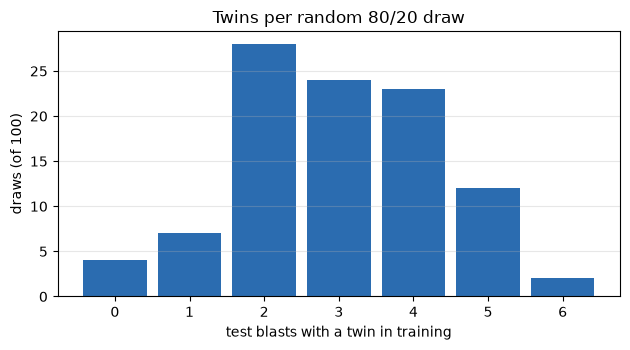

In [3]:
# The same count over 100 seeded draws
draws = bf.repeated_random_splits(train, n_repeats=100, seed=0)
twins = np.array([len(draw.detail["crossing_ids"]) for draw in draws])
test_size = len(draws[0].test)
rows = [
    ("draws with at least one twin", f"{int((twins > 0).sum())} of {len(twins)}"),
    ("mean twins per draw", f"{twins.mean():.2f} of {test_size}"),
    ("most twins in one draw", f"{twins.max()}"),
    ("mean share of the test set that is a twin", f"{twins.mean() / test_size:.1%}"),
]
show_table(["measure", "value"], rows)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.hist(twins, bins=np.arange(twins.max() + 2) - 0.5, color="#2b6cb0", rwidth=0.85)
ax.set_xlabel("test blasts with a twin in training")
ax.set_ylabel("draws (of 100)")
ax.set_title("Twins per random 80/20 draw")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

The histogram turns the anecdote into a rate: 96 of the 100 draws contain at least one twin, the mean draw has 2.99 twins among its 19 test blasts, which is 15.7 percent of the test set, and the worst draw has 6. A draw with no twin at all is the exception, not the rule. The figure does not show how fast the count would grow with a larger test share, and it counts only blasts whose seven inputs are exactly equal, so near-twins that differ in the third decimal are not in it: the 15.7 percent is a floor on what a random split lets through.

### Step 3: where the twins come from

Some blasts of a campaign were fired with the same design, so their seven inputs are identical and only the measured size differs. `duplicate_groups` finds them. The cell tabulates every group with its campaign and the spread of its measured sizes.

In [4]:
# The groups of blasts that share one input vector, with their measured sizes
groups = bf.duplicate_groups(train)
by_id = {blast.blast_id: blast for blast in train}
rows = []
for group in groups:
    sizes = [by_id[blast_id].x50_m for blast_id in group]
    rows.append((", ".join(group), by_id[group[0]].site, len(group), min(sizes), max(sizes)))
show_table(["blasts", "campaign", "size of group", "smallest x50 (m)",
            "largest x50 (m)"], rows)
print(f"groups: {len(groups)} | rows involved: {sum(len(group) for group in groups)}")

blasts,campaign,size of group,smallest x50 (m),largest x50 (m)
"En1, En2",Enusa,2,0.37,0.37
"En11, En12",Enusa,2,0.31,0.38
"En3, En5",Enusa,2,0.33,0.46
"En8, En9",Enusa,2,0.26,0.42
"Mr1, Mr3",Mrica,2,0.13,0.17
"Sm1, Sm2, Sm3",Soma,3,0.15,0.23
"Sm4, Sm5, Sm6, Sm7",Soma,4,0.22,0.28


groups: 7 | rows involved: 17


There are 7 groups and 17 rows involved, all in three campaigns: four groups in Enusa, one in Mrica and two in Soma, with sizes from 2 to 4. A group is one design fired more than once, and the measured sizes inside a group differ: En8 and En9 run from 0.26 m to 0.42 m, and the four Soma blasts of the last group from 0.22 m to 0.28 m. Identical inputs therefore do not mean identical outcomes, which is the reason the deduplicated split averages a group and does not drop all but one of its members.

### Step 4: the deduplicated split

`deduplicated_split` first collapses each group to one representative whose measured size is the mean of the group, then splits. Averaging is a stated choice: duplicated inputs carry real measurement scatter, and one row per distinct design is what a model should be asked to predict. The cell draws one split, repeats it over 100 seeds and counts the twins that remain.

In [5]:
# A deduplicated split: no input vector crosses the cut, over 100 draws
dedup = bf.deduplicated_split(train, seed=0)
print(dedup.protocol, f"| {len(dedup.train)} training, {len(dedup.test)} test")
print("engine note:", dedup.note)
dedup_draws = bf.repeated_deduplicated_splits(train, n_repeats=100, seed=0)
twins_dedup = []
for draw in dedup_draws:
    seen = {blast.features() for blast in draw.train}
    twins_dedup.append(sum(1 for blast in draw.test if blast.features() in seen))
rows = [
    ("random 80/20", f"{twins.mean():.2f}", f"{twins.max()}"),
    ("deduplicated", f"{np.mean(twins_dedup):.2f}", f"{max(twins_dedup)}"),
]
show_table(["protocol", "mean twins per draw", "most in one draw"], rows)

dedup-random | 70 training, 17 test
engine note: 97 rows collapsed to 87 distinct feature vectors before splitting


protocol,mean twins per draw,most in one draw
random 80/20,2.99,6
deduplicated,0.00,0


The engine collapses the 97 rows to 87 distinct input vectors and splits those, which leaves 70 for training and 17 for test. Over 100 draws the mean number of twins drops from 2.99 to 0.00 and the largest from 6 to 0, so the first property of a good split, no row on both sides, now holds in every draw. The table does not say the split is clean: it removes identical inputs, and the blasts of one campaign that differ in a single input are still on both sides. The next step measures that.

### Step 5: leave one site out

`leave_one_site_out` yields one split per campaign: that campaign is the test set and the other nine are training. The cell lists the ten folds, then builds a split that is not valid, the whole corpus as training and Enusa as test, and shows `assert_no_leakage` refuse it.

In [6]:
# The ten folds, and an invalid split that the leakage check must refuse
folds = list(bf.leave_one_site_out(train))
rows = [(f.detail["held_out_site"], len(f.test), len(f.train), f.detail["n_sites_in_train"]) for f in folds]
show_table(["held-out campaign", "test", "training", "campaigns in training"], rows)

enusa = tuple(blast for blast in train if blast.site == "Enusa")
invalid = bf.Split(protocol="leave-out-Enusa", train=tuple(train), test=enusa, seed=None, note="", detail={})
try:
    bf.splits.assert_no_leakage(invalid, allow_duplicate_features=False)
except bf.LeakageError as refusal:
    print("refused:", str(refusal)[:100], "...")

held-out campaign,test,training,campaigns in training
Akdaglar,22,75,9
Dongri-Buzurg,9,88,9
Enusa,12,85,9
Miami,6,91,9
Mrica,11,86,9
Murgul,7,90,9
Ozmert,7,90,9
Reocin,10,87,9
Reocin-UG,6,91,9
Soma,7,90,9


refused: leave-out-Enusa: 12 blast(s) on both sides: ['En1', 'En10', 'En11', 'En12', 'En2', 'En3', 'En4', 'En ...


The ten folds hold between 6 and 22 test blasts, Miami and Reocin-UG at the small end and Akdaglar at 22, and every fold trains on exactly 9 campaigns. The engine's refusal names the problem in a line: the invalid split puts 12 blasts on both sides, all of Enusa, and `assert_no_leakage` stops it before any model could be scored. The table does not say the folds are comparable in difficulty; a fold of 6 blasts and a fold of 22 give scores of very different precision, which the next notebooks take into account.

### Step 6: the dependence that deduplication leaves

Removing twins does not remove the shared campaign. For each test blast of the 100 deduplicated draws, the cell counts the training blasts that come from its own campaign, averages by campaign, and sets that against the zero of the leave-one-site-out folds. The number in brackets on each label is the campaign's size.

campaign,blasts,"training blasts of the same campaign, per test blast"
Akdaglar,22,16.9
Dongri-Buzurg,9,6.6
Enusa,12,5.6
Miami,6,4.1
Mrica,11,7.3
Murgul,7,4.7
Ozmert,7,4.9
Reocin,10,7.4
Reocin-UG,6,4.2
Soma,7,0.8


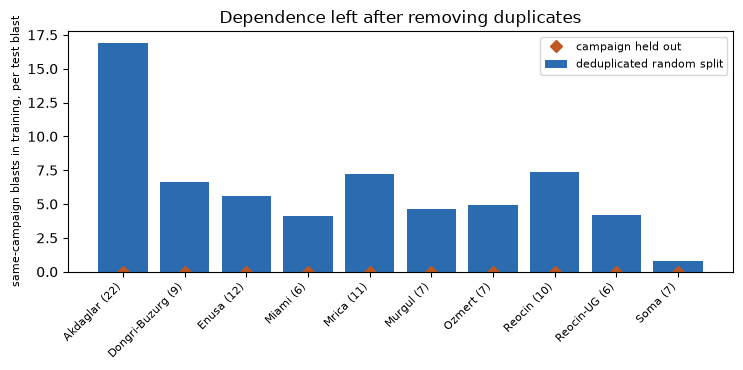

In [7]:
# What a deduplicated random split still gives each test blast: training blasts of its own campaign
campaigns = sorted({blast.site for blast in train})
mates = {campaign: [] for campaign in campaigns}
for draw in dedup_draws:
    in_training_by_campaign = Counter(blast.site for blast in draw.train)
    for blast in draw.test:
        mates[blast.site].append(in_training_by_campaign[blast.site])
averages = [np.mean(mates[campaign]) for campaign in campaigns]
sizes = Counter(blast.site for blast in train)
rows = [(campaign, sizes[campaign], f"{average:.1f}") for campaign, average in zip(campaigns, averages)]
show_table(["campaign", "blasts", "training blasts of the same campaign, per test blast"], rows)

fig, ax = plt.subplots(figsize=(7.4, 3.8))
position = np.arange(len(campaigns))
ax.bar(position, averages, color="#2b6cb0", label="deduplicated random split")
ax.plot(position, np.zeros(len(campaigns)), "D", color="#c05621", label="campaign held out")
labels = [f"{campaign} ({sizes[campaign]})" for campaign in campaigns]
ax.set_xticks(position, labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("same-campaign blasts in training, per test blast", fontsize=8)
ax.set_title("Dependence left after removing duplicates")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Without twins a random split still hands each test blast many blasts of its own campaign: on average 16.9 for Akdaglar, 7.4 for Reocin, 7.3 for Mrica and 5.6 for Enusa, and the lowest, Soma at 0.8, is low only because its seven blasts collapse into a few distinct designs. These are the blasts that share a rock mass, a rig and an explosive supply with the test blast, and the marks at zero show that holding the campaign out removes all of them. The figure counts shared campaign and not shared information, so it does not say how much any model profits from it; it says the second property of a good split is not met by any random split.

### Check against the committed benchmark

The only comparison with a committed artifact in this notebook: the duplicate groups found here must be the ones the offline bake wrote into `benchmark.json`.

In [8]:
# Check: the duplicate groups equal the ones the offline bake committed
committed_groups = json.loads(BENCHMARK.read_text(encoding="utf-8"))["duplicate_groups"]
found_groups = sorted(map(sorted, bf.duplicate_groups(train)))
print("same groups as the committed benchmark:", found_groups == sorted(map(sorted, committed_groups)))

same groups as the committed benchmark: True


## Results

**Answer:** a random 80/20 split of these 97 blasts has about 3 of its 19 test blasts already in training. In the first draw it is 4 of 19, over 100 draws 96 contain at least one twin, the mean is 2.99 per draw, which is 15.7 percent of the test set, and the worst draw has 6. The twins come from 7 groups of 17 blasts that repeat a design inside Enusa, Mrica and Soma. A deduplicated split removes every twin (0.00 per draw, 0 at most) but still leaves each test blast between 0.8 and 16.9 blasts of its own campaign in training, and only holding the campaign out brings that to zero.

**What this does not show.** No model is scored here, so the notebook does not say how much a score inflates because of twins or campaign-mates; the next notebook defines the score, and the level 3 notebook measures the gap on a published ensemble. The twin count also covers exact equality of the seven inputs only, and the ten folds are of very unequal size, from 6 to 22 blasts.

## Summary

- A random 80/20 split leaks: 96 of 100 draws carry at least one test blast with an identical input vector in training, 2.99 on average.
- Deduplicating removes the twins but not the shared campaign; only holding a whole campaign out leaves no test blast with a campaign-mate in training.
- The engine counts the leak and refuses an invalid leave-one-site-out split before any model is scored.
- Next: notebook 02 defines the score, the null model and the interval for a campaign held out.

## References

- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (cross-validation under dependent data)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (the random 80/20 protocol of the learned-predictor studies)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/